EDA по числовым признакам.

In [ ]:
import pandas as pd

df_train = pd.read_csv('DS/train.csv')

df_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Ужадим из датасета все категориальные признаки.

In [ ]:
cat_features = ["Name", "Sex", "Ticket", "Cabin", "Embarked"]
df_train = df_train.drop(columns=cat_features)

df_train.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
0,1,0,3,22.0,1,0,7.2500
1,2,1,1,38.0,1,0,71.2833
2,3,1,3,26.0,0,0,7.9250
3,4,1,1,35.0,1,0,53.1000
4,5,0,3,35.0,0,0,8.0500


Выведем информацию нашего датафрейма.

In [72]:
df_train.describe(include="all")

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


1) Из "mean" калонки "Survived" можно сделать вывод, что в датасете присутсвует дисбаланс классов (1 - 38%; 0 - 62%).
2) В "Pclass" у нас записан класс пассажира. Здесь присутсвует 3 значения (от 1го до 3го).
3) В графе "count" для столбца "Age" показано, что имеются пропуски, т.к. число не совпадает с числом пассажиров.
4) "SibSp" и "Parch" несут в себе почти одинаковый смысл. Количество родственников на борту. Теоретически, их можно объеденить в один столбец.
5) "Fare" - цена билета. Не имеет пропусков.

Первым делом, отобразим дисбаланс классов.

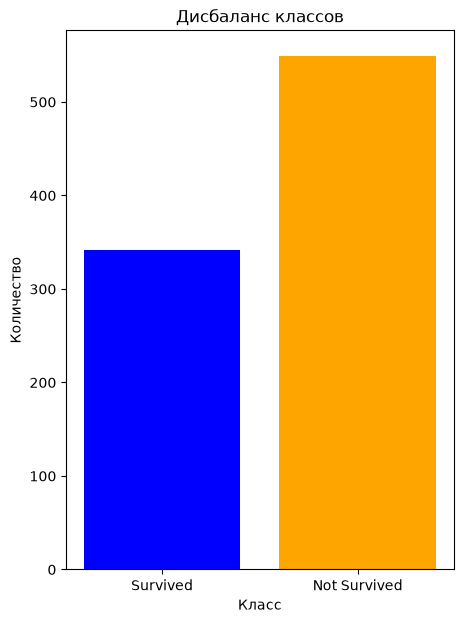

In [73]:
import matplotlib.pyplot as plt

survived_count = df_train["Survived"][df_train["Survived"] == 1].count()
not_survived_count = df_train["Survived"][df_train["Survived"] == 0].count()

plt.figure(figsize=(5, 7))
plt.bar(["Survived", "Not Survived"], [survived_count, not_survived_count], color=["blue", "orange"])
plt.title("Дисбаланс классов")
plt.xlabel("Класс")
plt.ylabel("Количество")
plt.show()


Теоретически, класс пассажира на борту зависит от стоимости его билета, а значит, что эти признаки могут сильно коррелировать.
Посчитаем корреляцию для класса и стоимость билета.

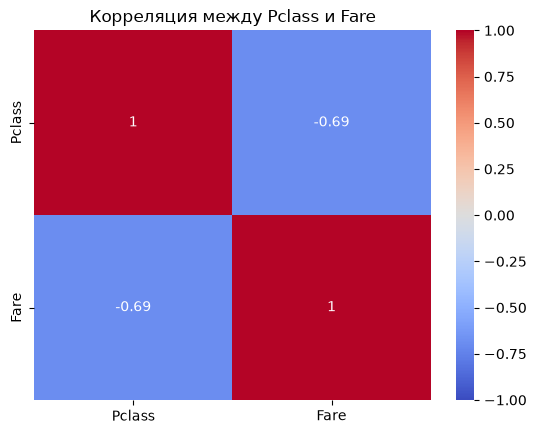

In [74]:
import seaborn as sns

correlation_matrix = df_train[["Pclass", "Fare"]].corr(method="spearman")
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция между Pclass и Fare")
plt.show()

Как видно, корреляция имеется, но не слишком сильная.

Далее посмотрим распределение класса "Survived" для каждого отдельного признака.

Text(0, 0.5, 'N')

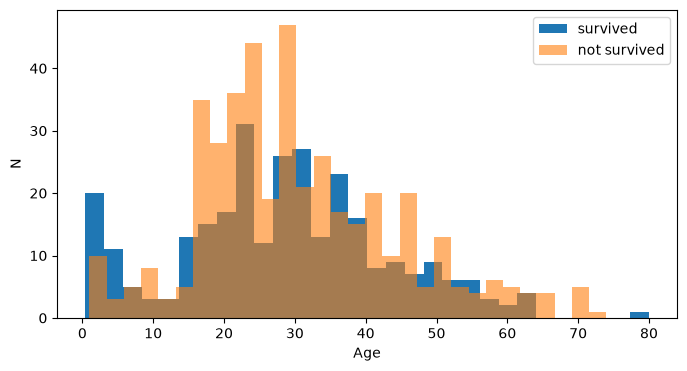

In [75]:
plt.figure(figsize=(8, 4))
not_nan_age = df_train[df_train["Age"].notna()]
sur_age = not_nan_age[not_nan_age["Survived"] == 1]
not_sur_age = not_nan_age[not_nan_age["Survived"] == 0]

plt.hist(sur_age["Age"], bins=30, alpha=1, label='survived')
plt.hist(not_sur_age["Age"], bins=30, alpha=0.6, label='not survived')
plt.xlabel('Age')
plt.legend()
plt.ylabel('N')

<Figure size 800x400 with 0 Axes>

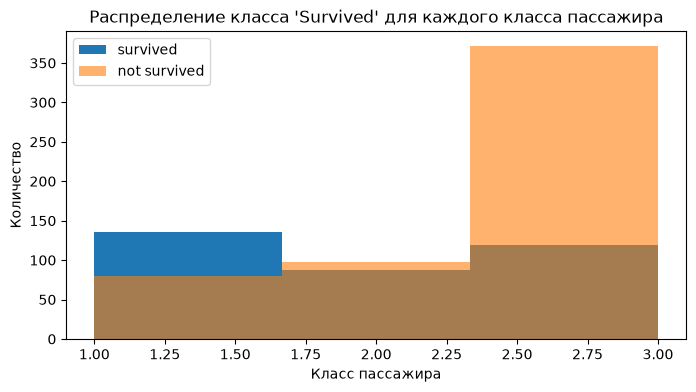

<Figure size 800x400 with 0 Axes>

<Figure size 800x400 with 0 Axes>

In [76]:
plt.figure(figsize=(8, 4))

sur_pclass = df_train[df_train["Survived"] == 1]
not_sur_pclass = df_train[df_train["Survived"] == 0]

plt.figure(figsize=(8, 4))
plt.hist(sur_pclass["Pclass"], bins=3, alpha=1, label='survived')
plt.hist(not_sur_pclass["Pclass"], bins=3, alpha=0.6, label='not survived')
plt.title("Распределение класса 'Survived' для каждого класса пассажира")
plt.xlabel("Класс пассажира")
plt.ylabel("Количество")
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))


Как видно, Смерность среди 3го класса пассажиров намного выше, чем в других.

Сделаем тоже самое, но для цены билета.

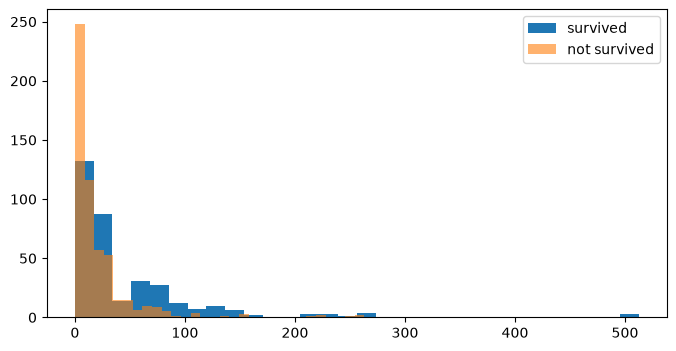

In [77]:
sur_fare = df_train[df_train["Survived"] == 1]
not_sur_fare = df_train[df_train["Survived"] == 0]

plt.figure(figsize=(8, 4))
plt.hist(sur_fare["Fare"], bins=30, alpha=1, label='survived')
plt.hist(not_sur_fare["Fare"], bins=30, alpha=0.6, label='not survived')
plt.legend()
plt.show()

Из последних двух графиков можно сделать вывод, что спасались, в первую очередь, богатые и статусные люди, тогда как распределение по возрасту среди выжевших и погибших примерно совпадает.

Дале проведем анализ по количеству родственников на борту.

In [78]:
df_train["Family"] = df_train["SibSp"] + df_train["Parch"]

df_train.drop(columns=["SibSp", "Parch"], inplace=True)

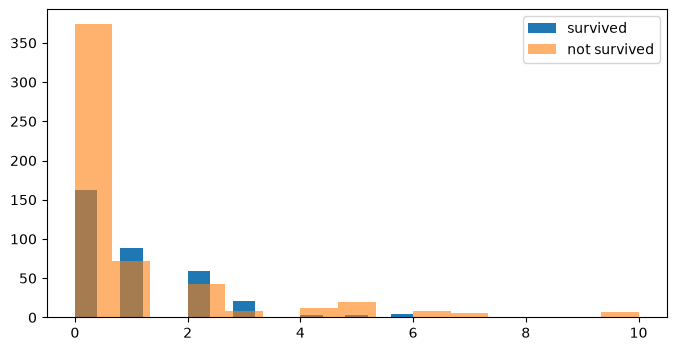

In [79]:
plt.figure(figsize=(8, 4))
not_nan_family = df_train[df_train["Family"].notna()]
sur_family = not_nan_family[not_nan_family["Survived"] == 1]
not_sur_family = not_nan_family[not_nan_family["Survived"] == 0]

plt.hist(sur_family["Family"], bins=15, alpha=1, label='survived')
plt.hist(not_sur_family["Family"], bins=15, alpha=0.6, label='not survived')
plt.legend()
plt.show()

Как видно, распределения повторяют друг друга, однако среди людей, у которых на борту было несколько родственников выживаемость выше, чем смертность.

У нас остался признак Age, в котором отсутсвует часть значений. Поступим так: Заменим все пропуски медианным значением и создадим новый признак, в котором укажим был ли указан возраст или нет (числовыми метками 0 и 1).

In [80]:
median_age = df_train["Age"].median()

df_train["Age_missing"] = df_train["Age"].isna().astype(int)
df_train["Age"] = df_train["Age"].fillna(median_age)

In [81]:
df_train.tail(5)

,PassengerId,Survived,Pclass,Age,Fare,Family,Age_missing
886,887,0,2,27.0,13.00,0,0
887,888,1,1,19.0,30.00,0,0
888,889,0,3,28.0,23.45,3,1
889,890,1,1,26.0,30.00,0,0
890,891,0,3,32.0,7.75,0,0


Удалим не нужный признак "Passengerid", который не несет никакой смысловой нагрузки.

In [82]:
df_train.drop(["PassengerId"], axis=1, inplace=True)

In [83]:
df_train.head(5)

,Survived,Pclass,Age,Fare,Family,Age_missing
0,0,3,22.0,7.2500,1,0
1,1,1,38.0,71.2833,1,0
2,1,3,26.0,7.9250,0,0
3,1,1,35.0,53.1000,1,0
4,0,3,35.0,8.0500,0,0


Теперь проделаем все те же операции, но уже с тестовой выборкой.

In [84]:
df_test = pd.read_csv('DS/test.csv')
df_test = df_test.drop(columns=cat_features)

df_test["Family"] = df_test["SibSp"] + df_test["Parch"]
df_test.drop(columns=["SibSp", "Parch"], inplace=True)

# Медианное значение берем из трейновой выборки
df_test["Age_missing"] = df_test["Age"].isna().astype(int)
df_test["Age"] = df_test["Age"].fillna(median_age)

df_test.drop(["PassengerId"], axis=1, inplace=True)

In [85]:
df_test.head(5)

,Pclass,Age,Fare,Family,Age_missing
0,3,34.5,7.8292,0,0
1,3,47.0,7.0000,1,0
2,2,62.0,9.6875,0,0
3,3,27.0,8.6625,0,0
4,3,22.0,12.2875,2,0


In [86]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Pclass       418 non-null    int64  
 1   Age          418 non-null    float64
 2   Fare         417 non-null    float64
 3   Family       418 non-null    int64  
 4   Age_missing  418 non-null    int64  
dtypes: float64(2), int64(3)
memory usage: 16.5 KB


Как видим, в признаке Fare отсутсвует одно значение. При этом в трейновой выборке не было пропусков, поэтому будщие модели не поймут, как себя вести с NaN. Заполним это значение статистически. Возьмем медиану по трейновой выборке.

In [87]:
fill_value = df_train["Fare"].median()
df_test["Fare"] = df_test["Fare"].fillna(fill_value)
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Pclass       418 non-null    int64  
 1   Age          418 non-null    float64
 2   Fare         418 non-null    float64
 3   Family       418 non-null    int64  
 4   Age_missing  418 non-null    int64  
dtypes: float64(2), int64(3)
memory usage: 16.5 KB


Оба датасета с количественными признаками готовы к работе.

In [88]:
df_train.to_csv('DS/train_cont.csv', index=False)
df_test.to_csv('DS/test_cont.csv', index=False)